![Banner](../images/09_05_banner_rs_hyperspect.png)


# Endmember Extraction and Spectral Unmixing

At 30 m a pixel is rarely one material: a city pixel holds roofs, trees and street; a field pixel
holds leaves, soil and shadow. Spectral unmixing models each pixel as a mixture of a few pure
spectra, the **endmembers**, and estimates their fractions. This notebook tests endmember extraction
and unmixing on a synthetic scene with known answers, then unmixes Portland with endmembers found
in the image, models endmember variability with MESMA, tries sparse unmixing with a large library
and checks fractions against the Pavia Centre ground truth.


## Overview

### The linear mixing model

If materials occupy separate patches of a pixel and light interacts with only one before reaching
the sensor, the pixel spectrum is a weighted sum of endmember spectra:

$$\mathbf{x} = \sum_{k=1}^{p} a_k \mathbf{e}_k + \mathbf{n}, \qquad a_k \ge 0, \qquad \sum_k a_k = 1$$

The two constraints (abundance non negativity, ANC, and sum to one, ASC) give four solvers:
unconstrained least squares (LS), sum to one (SCLS), non negative (NNLS) and fully constrained
(FCLS). Geometrically, the pixels fill a **simplex** whose vertices are the endmembers. Non linear
mixing (multiple scattering between leaves or in sand) is ignored, which is usually acceptable at
the 5 to 10 percent level.

### Finding endmembers

- **Pixel purity index (PPI)** (Boardman et al. 1995) projects the data on many random directions
  and counts how often each pixel lands at an extreme.
- **N-FINDR** (Winter 1999) searches for the pixels that span the simplex of largest volume.
- **Vertex component analysis (VCA)** (Nascimento and Bioucas-Dias 2005) repeatedly projects onto a
  direction orthogonal to the endmembers found so far and takes the extreme pixel.
- **ATGP** (Ren and Chang 2003) takes the pixel with the largest residual after projecting out the
  targets found so far.

All assume that pure pixels exist. The number of endmembers is usually set near the intrinsic
dimension (HySime, VD; notebook 09_05_03).

### Variability and large libraries

One spectrum per material is a simplification: vegetation differs in species and condition, roofs
in material and age, and illumination varies. **MESMA** (Roberts et al. 1998) tries many small
models, each with one spectrum per class plus **shade** (a zero spectrum that absorbs brightness
differences), and keeps the best fitting model per pixel. **Sparse unmixing** (SUnSAL, Iordache et
al. 2011) uses a large library and an L1 penalty, so that each pixel picks only a few members.


## Unmixing with GeoLattice

`hs.ppi`, `hs.atgp`, `hs.nfindr`, `hs.vca` and `hs.extract_endmembers` return the endmember
spectra, their pixel positions and a `SpectralLibrary`. `hs.unmix` solves LS, SCLS, NNLS or FCLS
for every pixel (NNLS and FCLS exactly for up to eight endmembers); `hs.mesma`, `hs.sparse_unmix`
and `hs.reconstruct` cover variability, large libraries and residual analysis.

### Learning objectives

1. Simulate a mixed scene and measure how well extraction and unmixing recover known endmembers
   and fractions.
2. Compare LS, SCLS, NNLS and FCLS and the effect of the constraints.
3. Extract endmembers from a real scene with N-FINDR and VCA and map their fractions.
4. Model endmember variability with MESMA and shade.
5. Unmix with a large library sparsely and count the active members.
6. Validate fractions against labelled pixels.

### Data

| Dataset | Use |
|---|---|
| Synthetic scene from `hs.synthetic_library` on Tanager bands | Known endmembers and fractions |
| Tanager urban scene (Portland), 300 by 300 pixel window | Real endmember extraction, FCLS, MESMA, sparse unmixing |
| Pavia Centre with ground truth | Fraction validation with class mean endmembers |

### Contents

- Setup
- A synthetic scene with known answers
- Endmember extraction on the synthetic scene
- Four solvers
- Endmembers of a city
- Fraction maps and residuals
- MESMA: variability and shade
- Sparse unmixing with a large library
- Checking fractions against labels
- Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
from geolattice.rsense import hyperspectral as hs  # hyperspectral cubes, readers and tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_05_HyperSpectral")  # data folder next to this notebook
TANAGER = DATA / "Tanger"  # Planet Tanager sample scenes
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed


def tanager_file(category, product="sr"):
    """Path of a Tanager product (sr or radiance) for a scene category folder."""
    return next((TANAGER / category).glob(f"*/*_ortho_{product}_hdf5.h5"))


print("GeoLattice", geolattice.__version__)  # library version used for this notebook

import time  # timing
import scipy.io  # Pavia ground truth
from scipy import ndimage as ndi  # smooth random fields

GeoLattice 0.3.49


## A synthetic scene with known answers

Four endmembers (green vegetation, soil, water and clay) on Tanager's good bands are mixed with
spatially smooth random fractions; each corner holds a 4 by 4 block of one pure material, and noise
with a standard deviation of 0.005 is added.


In [2]:
probe = hs.read_tanager(tanager_file("urban"), window=(slice(0, 1), slice(0, 1)))  # Tanager bands
w = hs.wavelengths(probe)
probe = probe.isel(band=np.flatnonzero(probe["good"].values & (w >= 400) & (w <= 2450)))
names = ["green_vegetation", "soil", "water", "clay_kaolinite"]
E = hs.synthetic_library(np.arange(400.0, 2451.0, 1.0)).resample(probe).subset(names).spectra  # (4, bands)
rng = np.random.default_rng(0)
H = W = 100
Z = np.stack([ndi.gaussian_filter(rng.normal(size=(H, W)), 4) for _ in range(4)], -1)  # smooth fields
A = np.exp(Z / Z.std() * 1.5); A /= A.sum(-1, keepdims=True)  # fractions that sum to one
for k, (r, c) in enumerate([(0, 0), (0, W - 4), (H - 4, 0), (H - 4, W - 4)]):
    A[r:r + 4, c:c + 4] = np.eye(4)[k]  # pure blocks in the corners
syn = hs.as_cube(np.einsum("yxk,kb->byx", A, E) + rng.normal(0, 0.005, (E.shape[1], H, W)), hs.wavelengths(probe))
print(syn.shape, "| pure pixels per material:", 16, "| mean fractions:", np.round(A.reshape(-1, 4).mean(0), 3))

(353, 100, 100) | pure pixels per material: 16 | mean fractions: [0.263 0.265 0.24  0.233]


## Endmember extraction on the synthetic scene

Each extractor is asked for four endmembers. Each found spectrum is paired with the closest true
endmember by spectral angle.


In [3]:
def match(found, truth):
    """Angle (deg) from each true endmember to its closest found spectrum."""
    f = found / np.linalg.norm(found, axis=1, keepdims=True)
    t = truth / np.linalg.norm(truth, axis=1, keepdims=True)
    return np.degrees(np.arccos(np.clip(t @ f.T, -1, 1))).min(1)


rows, found = [], {}
for name in ["ppi", "atgp", "nfindr", "vca"]:
    t0 = time.perf_counter()
    res = hs.extract_endmembers(syn, 4, method=name)  # spectra, positions and a library
    found[name] = res
    ang = match(res["spectra"], E)
    pure = np.mean([(A[r, c].max() > 0.99) for r, c in zip(res["row"], res["col"])])
    rows.append({"method": name, "seconds": round(time.perf_counter() - t0, 2), "pure pixels picked": pure,
                 **{f"angle to {n.split('_')[0]} (deg)": a for n, a in zip(names, ang)}})
pd.DataFrame(rows).set_index("method").round(2)

,seconds,pure pixels picked,angle to green (deg),angle to soil (deg),angle to water (deg),angle to clay (deg)
method,,,,,,
ppi,0.31,1.0,0.82,0.96,18.76,0.44
atgp,0.05,1.0,0.82,0.96,18.66,0.44
nfindr,0.26,1.0,0.79,0.96,18.76,0.47
vca,0.43,1.0,0.78,1.02,18.76,0.47


All four methods pick pure pixels, one in each corner block, and the angles to the true vegetation,
soil and clay spectra are below about one degree, the effect of the added noise. Water is the
exception at about 19 degrees: its reflectance (a few thousandths beyond 900 nm) is close to the
noise level, so even a perfectly pure water pixel has a noisy shape. Averaging several pure pixels,
or denoising first, helps dark endmembers. On this easy scene the cheap ATGP is as good as the
others; real scenes without pure pixels are harder.


## Four solvers


In [4]:
rows = []
for method in ["ls", "scls", "nnls", "fcls"]:
    ab = hs.unmix(syn, E, method=method)  # fractions per endmember plus rmse
    F = np.stack([ab[n].values for n in ab.data_vars if n != "rmse"], -1)
    rows.append({"method": method, "fraction RMSE": float(np.sqrt(np.mean((F - A) ** 2))),
                 "negative fractions": float((F < -1e-6).mean()), "sum to one error": float(np.abs(F.sum(-1) - 1).mean()),
                 "spectral RMSE": float(ab["rmse"].mean())})
pd.DataFrame(rows).set_index("method").round(4)

,fraction RMSE,negative fractions,sum to one error,spectral RMSE
method,,,,
ls,0.0216,0.0241,0.0358,0.005
scls,0.0029,0.0046,0.0000,0.005
nnls,0.0205,0.0000,0.0336,0.005
fcls,0.0029,0.0000,0.0000,0.005


All four solvers fit the spectra equally well, because the noise is the only misfit. They differ in
the fractions. Unconstrained LS gives a few percent negative fractions and sums that miss one by
about 0.04. NNLS removes the negative values but not the sum error, and its fractions are hardly
better. The sum to one constraint is the one that matters here: SCLS and FCLS cut the fraction error
by a factor of seven, and FCLS also removes the last negative values. Physically meaningful fractions need FCLS (or SCLS with a shade endmember,
used in MESMA below).


## Endmembers of a city

HySime suggested a signal subspace of a few tens of components for this window (notebook 09_05_03),
far more than the number of materials an analyst would name. Unmixing usually uses a handful of
endmembers; six are extracted here with N-FINDR and VCA.


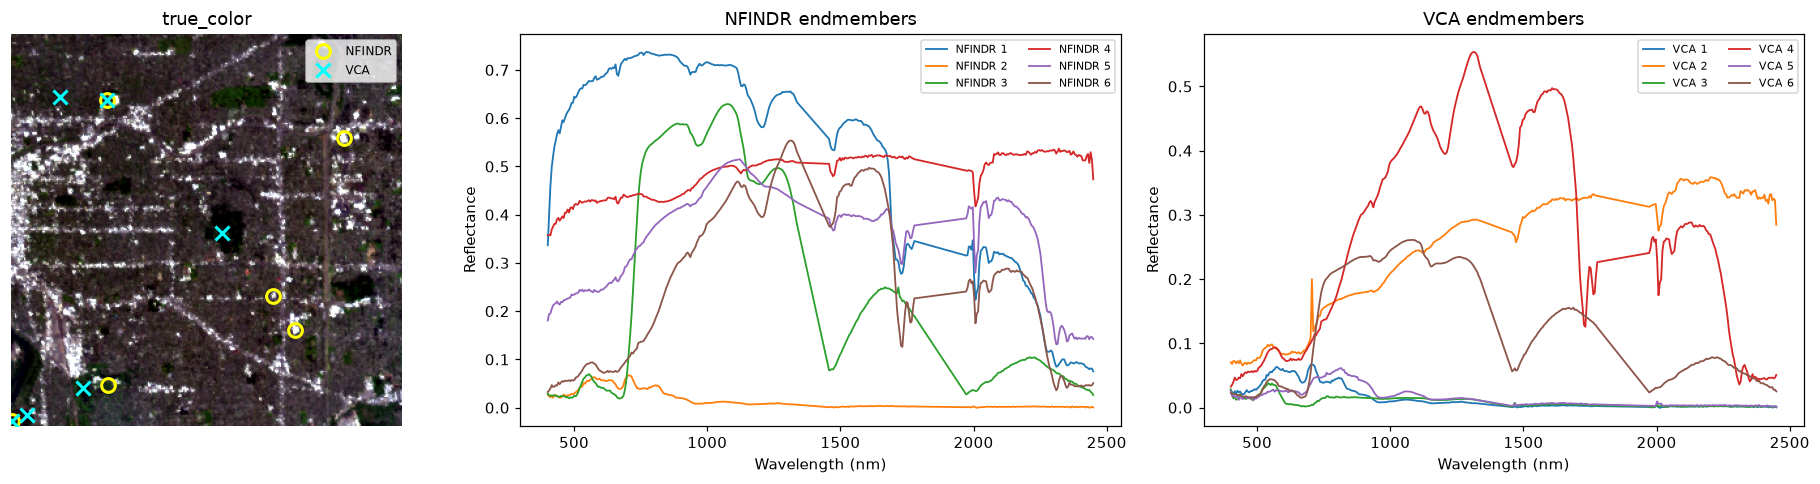

,method,endmember,row,col,NDVI,mean,SWIR/NIR
0,nfindr,1,226,217,0.020,0.513,0.753
1,nfindr,2,296,0,-0.326,0.015,0.149
2,nfindr,3,268,74,0.909,0.250,0.421
3,nfindr,4,79,255,-0.003,0.484,1.217
4,nfindr,5,200,200,0.207,0.354,0.979
5,nfindr,6,50,73,0.567,0.263,1.799
6,vca,1,296,0,-0.326,0.015,0.149
7,vca,2,48,37,0.352,0.245,1.845
8,vca,3,152,161,0.624,0.009,0.345
9,vca,4,50,73,0.567,0.263,1.799


In [5]:
urban = hs.drop_bad_bands(hs.read_tanager(tanager_file("urban"), window=(slice(319, 619), slice(285, 585))))
uwl = hs.wavelengths(urban)
ems = {m: hs.extract_endmembers(urban, 6, method=m) for m in ["nfindr", "vca"]}


def describe(s):
    """NDVI, mean reflectance and SWIR/NIR ratio of a spectrum, for naming endmembers."""
    b = lambda nm: s[np.argmin(np.abs(uwl - nm))]
    return {"NDVI": (b(860) - b(650)) / (b(860) + b(650)), "mean": s.mean(), "SWIR/NIR": b(1650) / b(860)}


fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
hs.plot_rgb(urban, "true_color", ax=axes[0])
tabs = []
for ax, (m, res) in zip(axes[1:], ems.items()):
    for i, s in enumerate(res["spectra"]):
        ax.plot(uwl, s, lw=1.2, label=f"{m.upper()} {i + 1}")
        tabs.append({"method": m, "endmember": i + 1, "row": int(res["row"][i]), "col": int(res["col"][i]), **describe(s)})
    axes[0].plot(res["col"], res["row"], "o" if m == "nfindr" else "x", mfc="none", ms=9, mew=2,
                 color="yellow" if m == "nfindr" else "cyan", label=m.upper())
    ax.set(title=f"{m.upper()} endmembers", xlabel="Wavelength (nm)", ylabel="Reflectance"); ax.legend(fontsize=7, ncol=2)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame(tabs).round(3)

The extracted spectra are the extremes of the scene, each a vertex of the data cloud. The table names
them: high NDVI means vegetation, very low mean reflectance water or deep shadow, and bright flat
spectra roofs or concrete. Extreme does not always mean typical: some vertices are single unusual
pixels (a bright roof, a building in shadow), which is why endmembers from algorithms should be
inspected, and why N-FINDR and VCA can disagree on a few of them.


## Fraction maps and residuals


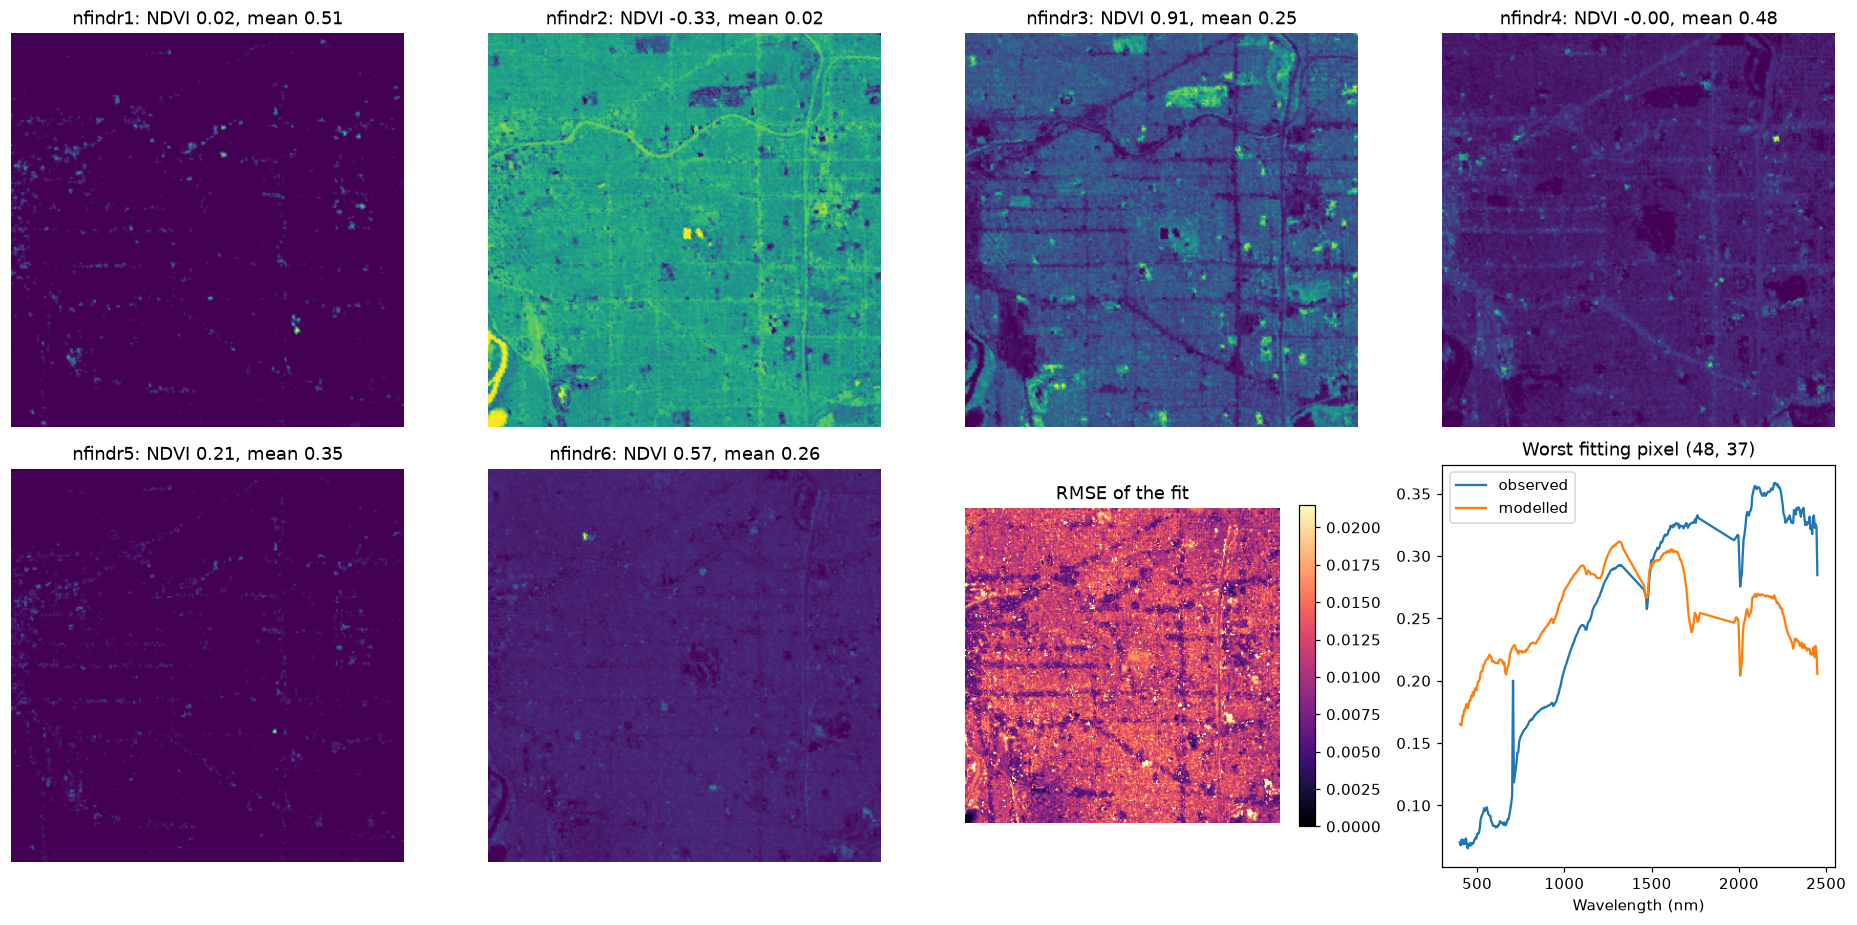

mean RMSE 0.0116 | 99th percentile 0.0215


In [6]:
em_lib = ems["nfindr"]["library"]  # N-FINDR endmembers as a library
ab = hs.unmix(urban, em_lib, method="fcls")  # fully constrained fractions
rec = hs.reconstruct(ab, em_lib, urban)  # modelled spectra
fig, axes = plt.subplots(2, 4, figsize=(17, 8.5))
for ax, n in zip(axes.ravel()[:6], em_lib.names):
    d = describe(em_lib.to_dict()[n])
    im = ax.imshow(ab[n], cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"{n}: NDVI {d['NDVI']:.2f}, mean {d['mean']:.2f}"); ax.axis("off")
im = axes[1, 2].imshow(ab["rmse"], cmap="magma", vmax=float(ab["rmse"].quantile(0.99)))
axes[1, 2].set_title("RMSE of the fit"); axes[1, 2].axis("off"); plt.colorbar(im, ax=axes[1, 2], shrink=0.8)
r, c = np.unravel_index(int(np.nanargmax(ab["rmse"].values)), ab["rmse"].shape)
axes[1, 3].plot(uwl, urban.values[:, r, c], label="observed"); axes[1, 3].plot(uwl, rec.values[:, r, c], label="modelled")
axes[1, 3].set(title=f"Worst fitting pixel ({r}, {c})", xlabel="Wavelength (nm)"); axes[1, 3].legend()
plt.tight_layout()
plt.show()
print(f"mean RMSE {float(ab['rmse'].mean()):.4f} | 99th percentile {float(ab['rmse'].quantile(0.99)):.4f}")

The maps show how extremes behave as endmembers. The dark endmember (water or deep shadow) takes a
large share of nearly every pixel: it acts as shade, absorbing the brightness differences between
pixels. The vegetation endmember follows parks and tree lined streets. The four bright endmembers
are single unusual pixels (bright roofs and surfaces), and their fractions are near zero almost
everywhere except around their own locations. The RMSE map shows the cost: errors of 0.01 to 0.02
over most of the built up area, and the worst fitting pixel has a SWIR shape that none of the six
endmembers can reproduce. Six extremes are a poor description of a city's typical materials; MESMA
below uses typical spectra instead.


## MESMA: variability and shade

MESMA needs a library with several spectra per class. Here each class gets three image spectra
chosen by index rules: green vegetation of low, median and high brightness, impervious surfaces from
bright roofs to dark pavement, and the water mean. Up to two classes plus shade are allowed per
pixel.


In [7]:
G, R, N, S1 = (hs.band_at(urban, wv).values for wv in (560, 650, 860, 1650))
ndvi, ndwi = (N - R) / (N + R), (G - N) / (G + N)
X = urban.values


def spectra_by_quantile(mask, score, qs):
    """Mean 3 x 3 spectra at the pixels of mask whose score is nearest each quantile."""
    out = []
    for q in qs:
        s = np.where(mask, score, np.nan)
        r, c = np.unravel_index(np.nanargmin(np.abs(s - np.nanquantile(s, q))), s.shape)
        out.append(X[:, max(r - 1, 0):r + 2, max(c - 1, 0):c + 2].reshape(X.shape[0], -1).mean(1))
    return np.array(out)


lib_m = {"vegetation": spectra_by_quantile(ndvi > 0.8, N, [0.1, 0.5, 0.9]),
         "impervious": spectra_by_quantile((ndvi < 0.12) & (ndwi < 0), S1, [0.05, 0.5, 0.97]),
         "water": X[:, ndwi > 0.3].mean(1, keepdims=True).T}
t0 = time.perf_counter()
ms = hs.mesma(urban, lib_m, max_classes=2, shade=True, max_rmse=0.03)
print(f"{len(ms.attrs['models'])} models tried in {time.perf_counter() - t0:.0f} s | "
      f"pixels with a model: {float((ms['model'] >= 0).mean()):.1%} | mean RMSE {float(ms['rmse'].mean()):.4f}")
used = pd.Series(ms["model"].values.ravel()).value_counts(normalize=True).head(6)
used.index = [ms.attrs["models"][i] if i >= 0 else "none" for i in used.index]
used.round(3).to_frame("share of pixels")

22 models tried in 5 s | pixels with a model: 96.7% | mean RMSE 0.0075


,share of pixels
vegetation_1 + impervious_0,0.643
vegetation_1 + impervious_1,0.122
vegetation_2 + impervious_0,0.049
vegetation_2 + impervious_1,0.045
none,0.033
vegetation_2,0.024


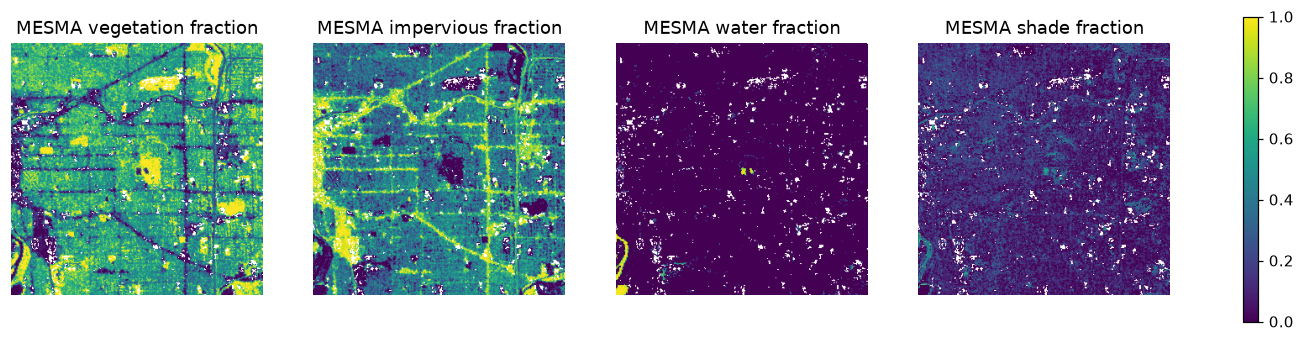

correlation of the MESMA vegetation fraction with the most vegetated N-FINDR fraction: 0.90


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, n in zip(axes, ["vegetation", "impervious", "water", "shade"]):
    im = ax.imshow(ms[n], cmap="viridis", vmin=0, vmax=1); ax.set_title(f"MESMA {n} fraction"); ax.axis("off")
plt.colorbar(im, ax=axes, shrink=0.8)
plt.show()
veg_f, imp_f = ab[em_lib.names[int(np.argmax([describe(s)["NDVI"] for s in em_lib.spectra]))]].values, ms["vegetation"].values
ok = np.isfinite(veg_f) & np.isfinite(imp_f)
print(f"correlation of the MESMA vegetation fraction with the most vegetated N-FINDR fraction: {np.corrcoef(veg_f[ok], imp_f[ok])[0, 1]:.2f}")

The model table shows which combinations the pixels chose: most of the window is explained by a
vegetation plus impervious mixture, as expected in a city, and the shade fraction absorbs brightness
differences between sunlit and shaded parts of a pixel. The class fractions are shade normalised,
so they say how much of the non shaded part of a pixel is vegetation. The vegetation map agrees well
with the N-FINDR vegetation fraction, but MESMA's fractions are easier to interpret because each
class has a name and several spectra.


## Sparse unmixing with a large library

ATGP extracts 30 candidate spectra from the window, more than any analyst would use. Sparse unmixing
lets each pixel choose a few of them.


sparse unmixing in 16 s | mean RMSE 0.0023 (FCLS with 6 endmembers: 0.0116)


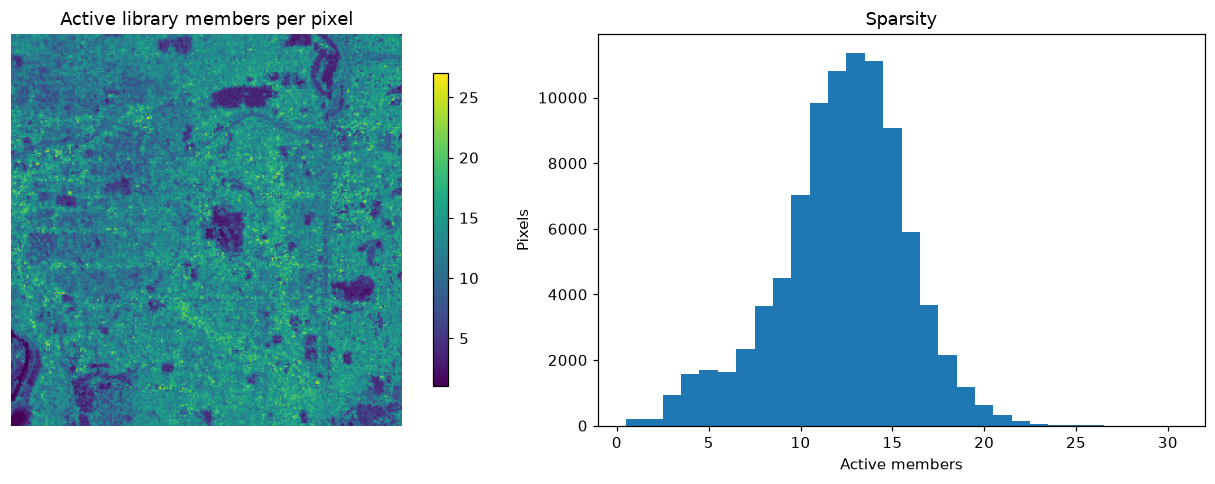

In [9]:
big = hs.atgp(urban, 30)["library"]  # 30 candidate endmembers
t0 = time.perf_counter()
sp = hs.sparse_unmix(urban, big, lam=1e-3, max_iter=600)
print(f"sparse unmixing in {time.perf_counter() - t0:.0f} s | mean RMSE {float(sp['rmse'].mean()):.4f} "
      f"(FCLS with 6 endmembers: {float(ab['rmse'].mean()):.4f})")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
im = axes[0].imshow(sp["n_active"], cmap="viridis"); axes[0].set_title("Active library members per pixel"); axes[0].axis("off")
plt.colorbar(im, ax=axes[0], shrink=0.8)
axes[1].hist(sp["n_active"].values.ravel(), bins=np.arange(0.5, 31.5, 1))
axes[1].set(xlabel="Active members", ylabel="Pixels", title="Sparsity")
plt.tight_layout()
plt.show()

With 30 candidates the fit is five times better than with six FCLS endmembers, but at this penalty
the solution is not very sparse: most pixels use 10 to 15 of the 30 members, and only parks and
water use a few. The penalty `lam` sets the trade off: larger values give sparser, less accurate
fits, and a value suited to the scale of the reflectance has to be chosen (see the exercises). Note that sparse
unmixing here does not enforce the sum to one constraint.


## Checking fractions against labels

The Pavia Centre ground truth labels pure looking pixels of nine classes. Using the mean spectrum of
each class as an endmember, FCLS should give each labelled pixel a high fraction of its own class.


In [10]:
arr = np.load(DATA / "Pavia/pavia.npy")
pavia = hs.as_cube(arr.transpose(2, 0, 1).astype("float32") / 10000, np.linspace(430, 860, arr.shape[2]))
gt = scipy.io.loadmat(DATA / "Pavia/Pavia_gt.mat")["pavia_gt"]
NAMES = ["water", "trees", "meadows", "self-blocking bricks", "bare soil", "asphalt", "bitumen", "tiles", "shadows"]
P = pavia.values.reshape(pavia.sizes["band"], -1)
class_lib = hs.library.from_dict({n: P[:, gt.ravel() == k + 1].mean(1) for k, n in enumerate(NAMES)}, hs.wavelengths(pavia))
t0 = time.perf_counter()
pab = hs.unmix(pavia, class_lib, method="fcls")  # nine endmembers: FISTA solver
print(f"unmixed {pavia.sizes['y'] * pavia.sizes['x']:,} pixels in {time.perf_counter() - t0:.0f} s")
own = pd.DataFrame({n: [np.median(pab[n].values[gt == k + 1]), np.mean(pab[n].values[gt == k + 1] > 0.5)]
                    for k, n in enumerate(NAMES)}, index=["median own fraction", "share with own fraction > 0.5"]).T
others = {n: pd.Series({m: float(np.mean(pab[m].values[gt == k + 1])) for m in NAMES if m != n}) for k, n in enumerate(NAMES)}
own["main competitor"] = [others[n].idxmax() for n in NAMES]  # class taking most of the rest
own["its mean fraction"] = [others[n].max() for n in NAMES]
own.round(3)

unmixed 783,640 pixels in 119 s


,median own fraction,share with own fraction > 0.5,main competitor,its mean fraction
water,0.939,1.000,shadows,0.058
trees,0.574,0.558,meadows,0.384
meadows,0.912,0.946,trees,0.046
self-blocking bricks,0.876,0.799,bitumen,0.097
bare soil,0.363,0.367,self-blocking bricks,0.346
asphalt,0.691,0.793,shadows,0.089
bitumen,0.789,0.779,self-blocking bricks,0.123
tiles,0.678,0.706,bare soil,0.235
shadows,0.959,1.000,water,0.045


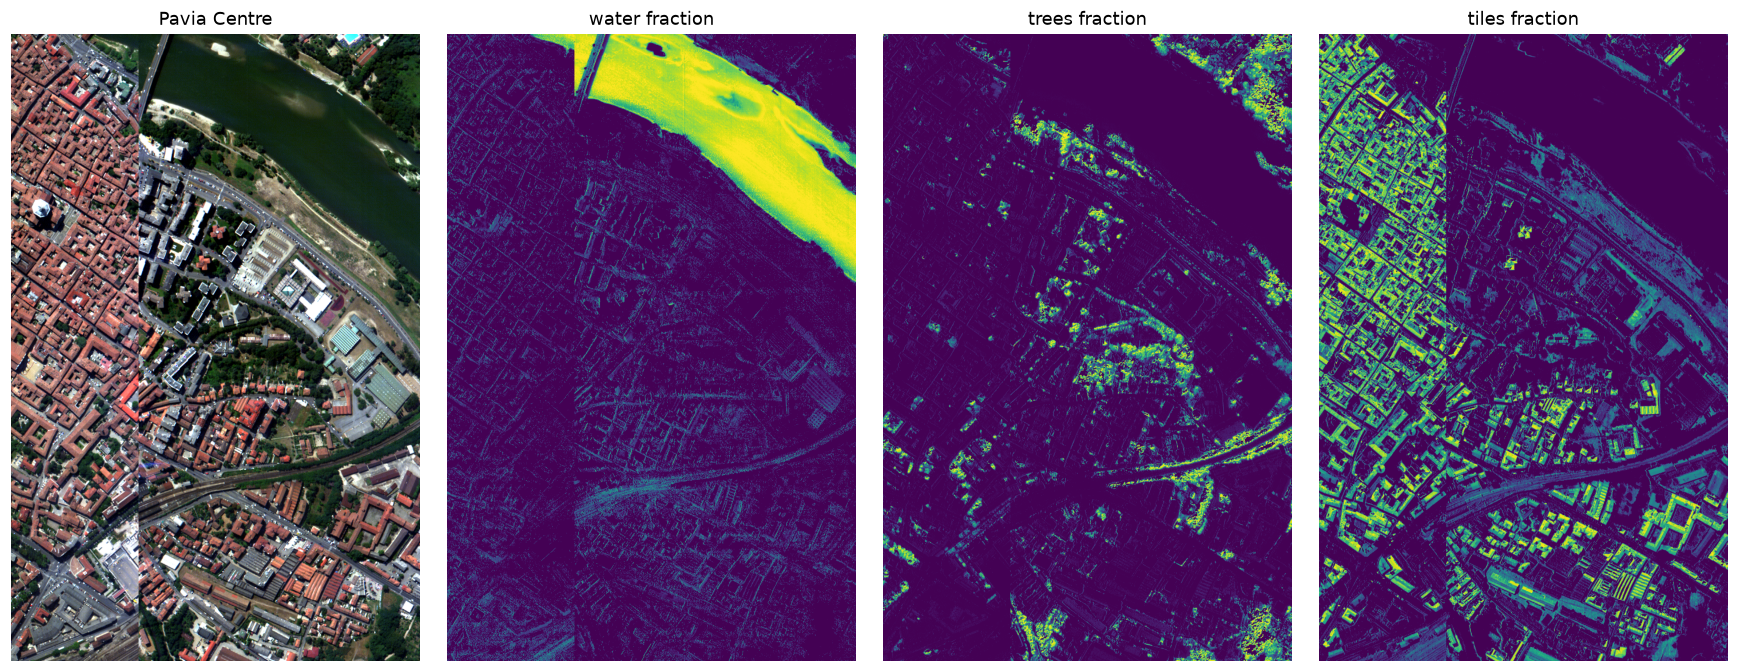

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 6))
hs.plot_rgb(pavia, (640, 550, 460), ax=axes[0], title="Pavia Centre")
for ax, n in zip(axes[1:], ["water", "trees", "tiles"]):
    ax.imshow(pab[n], cmap="viridis", vmin=0, vmax=1); ax.set_title(f"{n} fraction"); ax.axis("off")
plt.tight_layout()
plt.show()

Water, shadows, meadows and self-blocking bricks receive a median of 0.88 to 0.96 of their own
endmember in their labelled pixels. Bare soil and trees do worst (medians of about 0.36 and 0.57):
the "main competitor" column shows that meadows take about 0.38 of the tree pixels and
self-blocking bricks about 0.35 of the bare soil pixels, and tiles lose about 0.24 to bare soil. With one mean
spectrum per class and only VNIR bands, spectrally similar classes share their pixels, the same
reason they are the hardest to classify. The fraction maps give the gradual transitions (tree crowns over streets,
mixed roofs) that hard classification hides.


## Summary and exercises

**Key points**

- The linear mixing model with non negativity and sum to one constraints (FCLS) gives physically
  meaningful fractions; LS, SCLS and NNLS fit as well but violate one constraint or both.
- Extractors recover endmembers when pure pixels exist (dark ones stay noisy); on real scenes they
  return the extremes of the data, which may be rare pixels rather than typical materials.
- Residual (RMSE) maps show where the endmember set is incomplete.
- MESMA with shade handles variability within classes and brightness differences; sparse unmixing
  fits better with a large library, but its sparsity depends on the penalty.
- Class mean endmembers validated on labelled pixels show which materials a sensor can separate.

**`geolattice.rsense.hyperspectral` functions used:** `synthetic_library`, `as_cube`,
`extract_endmembers` (`ppi`, `atgp`, `nfindr`, `vca`), `unmix`, `reconstruct`, `mesma`,
`sparse_unmix`, `atgp`, `read_tanager`, `drop_bad_bands`, `band_at`, `plot_rgb`, `library.from_dict`.

**Exercises**

1. Raise the synthetic noise to 0.02 and remove the pure corner blocks. How do the extractors do?
2. Extract 4, 8 and 12 N-FINDR endmembers for Portland and plot the mean RMSE against the number.
3. Run MESMA with `max_classes=3`. Which pixels choose three class models?
4. Change `lam` in `sparse_unmix` to 1e-4 and 1e-2 and compare sparsity and RMSE.
5. Unmix Pavia with class medians instead of means. Do the confused classes improve?
